# Maestría en Ciencia de Datos | Programación I

## Limpieza y validación de datos textuales en Python

Este documento recopila las actividades, códigos y respuestas correspondientes a la Práctica de la Unidad 3.

---

Elaborado por: Gloria Viridiana Ruesga Rodriguez


In [1]:
# DATOS INICIALES DEL EJERCICIO

registros = [
    "T001 | ΑΝΑ | ΑNA@EJEMPLO.ORG | Datos | 12",
    "T002 | luis | luis@ejemplo.org | programacion | 8",
    "T003 | MARTA | marta.ejemplo.org | datos | 16",
    "T004 |pablo | pablo@ejemplo.org | DATOS | 15",
    "T005 | ELENA | elena@ejemplo.org | visualizacion | 10",
    "T006 | ivan | ivan@ejemplo.org | programacion | 20",
    "T007 | rosa | rosa@ejemplo.org | datos | abc",
    "T008 | hugo | hugo@ejemplo.org | visualizacion | 25",
    "T009 | sara | sara@ejemplo.org | datos| 18",
    "T010 | omar | omar@ejemplo.org | programacion|-3",
    "T011 | luz | visualizacion | 11",
    "T012 | noe | noe@ejemplo.org | visualizacion | 22"
]

# Esquema de cada línea: identificador | nombre | correo | categoría | minutos. El separador es |.
# En este ejercicio los campos no contienen ese carácter dentro de su contenido.

---

### Actividad 1: Listas e Índices

**Diagnóstico inicial:**
1. **¿`input()` devuelve texto o números?** 
   Devuelve siempre una cadena de texto (`str`).
2. **¿Qué diferencia existe entre una lista y una cadena?** 
   Una lista es una colección mutable de elementos ordenados que pueden ser de diversos tipos, mientras que una cadena es una secuencia inmutable de caracteres.
3. **¿Qué sucede al comparar `"20" < "8"`?** 
   Devuelve `True`. Las cadenas se comparan lexicográficamente carácter por carácter según su valor en la tabla de códigos; el carácter '2' es menor que '8'.

**Puntos de control y respuestas prácticas:**
- `len(registros)` mide la cantidad total de elementos (tickets) en la lista, mientras que `len(registros[0])` mide la cantidad de caracteres que componen la cadena de texto de ese primer elemento.
- `"T001" in registros` da `False` porque busca un elemento exacto dentro de la lista, en tanto que `"T001" in registros[0]` da `True` al buscar una subcadena dentro del primer texto.
- `ticket[0:3]` devuelve `"TOO"` debido a que el extremo derecho del slice no se incluye.

In [2]:
# Ejemplo guiado de cinco minutos

campos = ["id", "nombre", "correo", "categoria", "minutos"]
campos.insert(2, "origen")
retirado = campos.pop(2)
print("================ Ejemplo guiado ================")
print(retirado) # origen
print("correo" in campos) # True
print(campos[:3]) # id, nombre, correo
print(campos + ["estado"]) # nueva lista
print(["pendiente"] * 2) # repeticion

================ Ejemplo guiado ================
origen
True
['id', 'nombre', 'correo']
['id', 'nombre', 'correo', 'categoria', 'minutos', 'estado']
['pendiente', 'pendiente']


In [3]:
# 1. Copia, append, pop y verificación
copia = registros[:]
copia.append("PRUEBA")
retirado = copia.pop()
print("¿Conservan 12 elementos?", len(registros) == 12, len(copia) == 12)

# 2. Extracción y medición
print("Primer registro:", registros[0])
print("Último registro:", registros[-1])
print("Tres primeros:", registros[:3])
print("Longitud de la lista de registros:", len(registros))
print("Longitud del primer registro (caracteres):", len(registros[0]))
# Explicación: len(registros) mide la cantidad de elementos (tickets) en la lista, 
# mientras que len(registros[0]) mide la cantidad de caracteres que componen la cadena de texto de ese primer elemento.

# 3. Pertenencia vs Subcadena
print("¿'T001' in registros?:", "T001" in registros) # False, porque busca un elemento exacto en la lista
print("¿'T001' in registros[0]?:", "T001" in registros[0]) # True, porque busca una subcadena dentro del primer texto

# 4. Operaciones con Slices en un ticket
ticket = "T001"
print("ticket[0]:", ticket[0])       # "T"
print("ticket[1:]::", ticket[1:])     # "001"
print("ticket[-1]:", ticket[-1])     # "1"
print("ticket[0:3]:", ticket[0:3])   # "TOO" (el extremo derecho no se incluye)

¿Conservan 12 elementos? True True
Primer registro: T001 | ΑΝΑ | ΑNA@EJEMPLO.ORG | Datos | 12
Último registro: T012 | noe | noe@ejemplo.org | visualizacion | 22
Tres primeros: ['T001 | ΑΝΑ | ΑNA@EJEMPLO.ORG | Datos | 12', 'T002 | luis | luis@ejemplo.org | programacion | 8', 'T003 | MARTA | marta.ejemplo.org | datos | 16']
Longitud de la lista de registros: 12
Longitud del primer registro (caracteres): 41
¿'T001' in registros?: False
¿'T001' in registros[0]?: True
ticket[0]: T
ticket[1:]:: 001
ticket[-1]: 1
ticket[0:3]: T00


---

### Actividad 2: Limpieza de Cadenas

**Conceptos clave y respuestas:**
- **Inmutabilidad:** Métodos como `strip()`, `lower()` y `replace()` no modifican la cadena original; devuelven una cadena nueva que debe ser almacenada.
- **Uso de `find("#")`:** Si se utiliza el resultado de `find("#")` (que devuelve `-1` si no encuentra el carácter) como índice directamente sin evaluarlo, se provocará un error lógico o un `IndexError` al apuntar al final de la cadena.
- **Efectos de `capitalize()`:** Al aplicarlo sobre un texto como `"IA APLICADA"`, produce `"Ia aplicada"`, alterando y destruyendo mayúsculas sostenidas o acrónimos institucionales.
- **Diferencia técnica:** `len(texto)` es una función incorporada global, mientras que `texto.lower()` es un método asociado a la clase de objetos de tipo cadena (`str`).

In [4]:
# Ejemplo guiado del primer registro
linea = registros[0]
campos = linea.split("|")
campos = [campo.strip() for campo in campos]
campos[0] = campos[0].upper()
campos[2] = campos[2].lower()
campos[3] = campos[3].lower()
print(campos)
print(" | ".join(campos))
print(f"Ticket ({campos[0]}): categoría {campos[3]}")

['T001', 'ΑΝΑ', 'αna@ejemplo.org', 'datos', '12']
T001 | ΑΝΑ | αna@ejemplo.org | datos | 12
Ticket (T001): categoría datos


In [5]:
# Ejercicios por resolver

# 5. Con texto = "Ciencia    de     Datos"
texto = "Ciencia    de     Datos"
texto_limpio = " ".join(texto.split())
print("Con split y join:", texto_limpio)
print("Con strip():", texto.strip()) # strip solo quita extremos, no espacios internos múltiples

# 6. Extracción de usuario y dominio de un correo
correo = "ana@ejemplo.org"
pos_arroba = correo.find("@")
pos_punto = correo.rfind(".")
usuario = correo[:pos_arroba]
dominio = correo[pos_arroba + 1:]
print(f"find('@')={pos_arroba}, rfind('.')={pos_punto}")
print(f"Usuario: {usuario}, Dominio: {dominio}")

# 7. Comprobar find("#")
print("find('#'):", correo.find("#")) # Devuelve -1. Usarlo como índice sin revisar provocaría un error lógico o IndexError.

# 8. Reemplazos y capitalización
etiqueta = "visualizacion-datos"
etiqueta_mod = etiqueta.replace("-", " ").upper()
print("Etiqueta modificada:", etiqueta_mod)
print("Capitalize en 'IA APLICADA':", "IA APLICADA".capitalize()) 
# capitalize() convierte la primera letra en mayúscula y el resto en minúscula, alterando acrónimos.

# 9. Métodos y funciones
print("Diferencia: len(texto) es una función incorporada, mientras que texto.lower() es un método de la clase str.")

Con split y join: Ciencia de Datos
Con strip(): Ciencia    de     Datos
find('@')=3, rfind('.')=11
Usuario: ana, Dominio: ejemplo.org
find('#'): -1
Etiqueta modificada: VISUALIZACION DATOS
Capitalize en 'IA APLICADA': Ia aplicada
Diferencia: len(texto) es una función incorporada, mientras que texto.lower() es un método de la clase str.


---

### Actividad 3: Validación y Decisiones

**Discusión sobre tiempo ausente:**
- **¿Reemplazar un tiempo ausente por cero equivale a corregirlo?** 
  No. Asignar cero significaría registrar un tiempo real de atención que jamás ocurrió, alterando artificialmente las métricas de desempeño. Por ello, la estrategia correcta separa los registros rechazados y conserva su texto original para auditoría.

**Pseudocódigo de validación:**
Se establece un orden riguroso de evaluación:
1. Conteo exacto de campos.
2. Formato del identificador (`T` + 3 dígitos).
3. Verificación de nombre no vacío.
4. Validación estricta del correo (una sola arroba, sin espacios, dominio con punto y segmentos no vacíos).
5. Pertenencia de la categoría al catálogo permitido.
6. Rango numérico válido para los minutos (0 a 180).

### Procedimiento para validar una línea:

Procedimiento validar_linea(linea):

    Separar linea usando "|" en un arreglo llamado campos
    Si longitud de campos != 5 entonces:
        Devolver Nulo, "numero de campos"
    Fin Si
    
    Limpiar espacios en cada campo de campos mediante strip()
    Asignar campos a: ticket, nombre, correo, categoria, tiempo
    
    Normalizar ticket a mayúsculas, correo y categoría a minúsculas
    
    Si ticket no cumple formato (empieza con 'T' seguido de 3 dígitos) entonces:
        Devolver Nulo, "identificador"
    Fin Si
    
    Si nombre está vacío entonces:
        Devolver Nulo, "nombre vacio"
    Fin Si
    
    Si correo no es válido (debe contener exactamente una '@', sin espacios, y dominio con al menos un punto) entonces:
        Devolver Nulo, "correo"
    Fin Si
    
    Si categoría no pertenece a ["datos", "programacion", "visualizacion"] entonces:
        Devolver Nulo, "categoria"
    Fin Si
    
    Si tiempo no es un valor numérico entero válido entonces:
        Devolver Nulo, "minutos no enteros o negativos"
    Fin Si
    
    Convertir tiempo a entero (minutos)
    Si minutos > 180 entonces:
        Devolver Nulo, "minutos fuera de rango"
    Fin Si
    
    Devolver [ticket, nombre, correo, categoria, minutos], ""
Fin Procedimiento

In [6]:
#[Inicio] 
#    │
#    ▼
#[Leer minutos]
#    │
#    ▼
#   < min <= 15 ? >
#   /             \
#(Sí)             (No)
#  │                │
#  ▼                ▼
#[ "En tiempo" ]  [ "Fuera de tiempo" ]
#  \                /
#   ▼              ▼
#     [ Fin del flujo ]

---

### Actividad 4: Funciones Reutilizables y Procesamiento

**Criterios de logro y resultados esperados:**
- El procesamiento iterativo sobre el conjunto de datos de entrada debe concluir exactamente con **8 registros aceptados y 4 rechazados**.
- **Motivos de rechazo identificados:**
  - `T003`: Correo sin `@`.
  - `T007`: Minutos no numéricos (`abc`).
  - `T010`: Minutos negativos (`-3`).
  - `T011`: Correo vacío o formato incompleto.

In [7]:
def limpiar_texto(texto):
    return "".join(texto.strip().split())

def correo_basico(correo):
    if correo.count("@") != 1 or " " in correo:
        return False
    usuario, dominio = correo.split("@")
    partes = dominio.split(".")
    return (usuario != "" and len(partes) >= 2 
            and all(parte != "" for parte in partes))

categorias = ["datos", "programacion", "visualizacion"]

def procesar_registro(linea):
    campos = linea.split("|")
    if len(campos) != 5:
        return None, "numero de campos"
    
    campos = [limpiar_texto(c) for c in campos]
    ticket, nombre, correo, categoria, tiempo = campos
    ticket = ticket.upper()
    correo = correo.lower()
    categoria = categoria.lower()
    
    if not (len(ticket) == 4 and ticket.startswith("T") 
            and ticket[1:].isascii() and ticket[1:].isdigit()):
        return None, "identificador"
    if nombre == "":
        return None, "nombre vacio"
    if not correo_basico(correo):
        return None, "correo"
    if categoria not in categorias:
        return None, "categoria"
    if not (tiempo.isascii() and tiempo.isdigit()):
        return None, "minutos no enteros o negativos"
    
    minutos = int(tiempo)
    if minutos > 180:
        return None, "minutos fuera de rango"
        
    return [ticket, nombre, correo, categoria, minutos], ""

aceptados = []
rechazados = []

for linea in registros:
    fila, motivo = procesar_registro(linea)
    if fila is None:
        rechazados.append([linea, motivo])
    else:
        aceptados.append(fila)

print(f"Total aceptados: {len(aceptados)}")
print(f"Total rechazados: {len(rechazados)}")

Total aceptados: 8
Total rechazados: 4


---

### Actividad 5: Indicadores y Visualización

**Interpretación de resultados y sesgos:**
1. **Volumen:** Las categorías **datos** y **visualización** concentran la mayor demanda con 3 solicitudes cada una, mientras que **programación** registra 2.
2. **Limitación de la media:** El promedio de 16.25 minutos describe únicamente a los 8 registros aceptados, no al total de solicitudes recibidas.
3. **Denominadores:** Es crítico mantener la distinción; el porcentaje de aceptación utiliza como denominador el total de registros de entrada (12), mientras que la media de atención emplea el subconjunto de elementos válidos (8).
4. **Sesgo de exclusión:** Eliminar registros defectuosos sin un análisis complementario puede encubrir fallas operativas sistemáticas en el canal de captura original.

Aceptados: 8/12 (66.67%)
Rechazados: 4
Tiempo promedio: 16.25 min
Conteos (datos / programacion / visualizacion): [3, 2, 3]


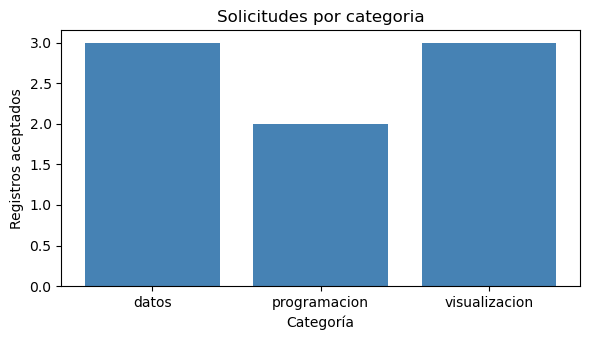

In [8]:
import matplotlib.pyplot as plt

def clasificar_tiempo(minutos, limite=15):
    if minutos <= limite:
        return "en tiempo"
    return "fuera de tiempo"

tiempos = [fila[4] for fila in aceptados]
n_validos = len(aceptados)
n_total = len(registros)
porcentaje = 100 * n_validos / n_total if n_total else 0
promedio = sum(tiempos) / n_validos if n_validos else 0

print(f"Aceptados: {n_validos}/{n_total} ({porcentaje:.2f}%)")
print(f"Rechazados: {len(rechazados)}")
print(f"Tiempo promedio: {promedio:.2f} min")

conteos = []
for categoria in categorias:
    cantidad = 0
    for fila in aceptados:
        if fila[3] == categoria:
            cantidad += 1
    conteos.append(cantidad)

print("Conteos (datos / programacion / visualizacion):", conteos)

def graficar_barras(etiquetas, valores, titulo, color):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(etiquetas, valores, color=color)
    ax.set_title(titulo)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("Registros aceptados")
    fig.tight_layout()
    return fig, ax

fig, ax = graficar_barras(categorias, conteos, "Solicitudes por categoria", "steelblue")
fig.savefig("solicitudes_por_categoria.png", dpi=150)
plt.show()

---

### Preguntas para la Defensa Individual

1. **¿Por qué `strip()` no elimina todos los espacios internos?**
   Porque está diseñado exclusivamente para remover caracteres en blanco de los extremos (inicio y fin) de una cadena, manteniendo intactos los espacios que se encuentran en medio.
2. **¿Qué diferencia hay entre devolver un dato e imprimirlo?**
   `return` transfiere un valor para su reutilización lógica en el programa, en tanto que `print()` emite una representación visual en la consola sin retornar objetos utilizables.
3. **¿Qué error produce tratar minutos como texto?**
   Impide realizar operaciones de agregación matemática (como sumatorias o promedios) y genera evaluaciones de orden lexicográfico erróneas frente a los límites numéricos.
4. **¿Por qué conservar los registros rechazados?**
   Para garantizar la trazabilidad completa, permitir auditorías de calidad de datos y evitar la pérdida silenciosa de información cruda.
5. **¿Qué limita la validación de correos utilizada?**
   Se limita a una verificación sintáctica elemental ( conteo de arroba y estructura de puntos), sin comprobar la existencia real del buzón en el servidor de correo.